In [1]:
import zipfile

with zipfile.ZipFile('/content/retail-stockout-inventory-analysis-main.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

In [2]:
import os
os.listdir('/content/')

['.config',
 'retail-stockout-inventory-analysis-main.zip',
 'retail-stockout-inventory-analysis-main',
 'sample_data']

In [3]:
import os

os.listdir('/content/retail-stockout-inventory-analysis-main/data/processed')

['Retail_inventory_analysis_cleaned.xlsx', 'README.md']

In [5]:
import pandas as pd

df = pd.read_excel(
    '/content/retail-stockout-inventory-analysis-main/data/processed/Retail_inventory_analysis_cleaned.xlsx',
    sheet_name='inventory_ledger_cleaned'
)

In [6]:
df.head()

,store_id,product_id,category,week_start,month,opening_stock,units_received,spoilage_units,units_sold,closing_stock,stockout_flag,lost_sales_units,reorder_point,safety_stock,supplier_id
0,S001,P025,Personal Care,2025-02-17,2025-02,647,0,1,64,582,0,0,167,21,SUP009
1,S001,P008,Packaged Foods,2025-10-13,2025-10,636,0,1,64,571,0,0,179,22,SUP004
2,S014,P014,Beverages,2025-09-15,2025-09,141,0,1,28,112,0,0,71,12,SUP006
3,S010,P012,Packaged Foods,2025-02-10,2025-02,230,105,0,18,212,0,0,54,7,SUP004
4,S003,P021,Household Essentials,2025-09-22,2025-09,112,0,0,36,76,0,0,94,24,SUP007


In [7]:
df.shape

(17160, 15)

In [8]:
df.columns

Index(['store_id', 'product_id', 'category', 'week_start', 'month',
       'opening_stock', 'units_received', 'spoilage_units', 'units_sold',
       'closing_stock', 'stockout_flag', 'lost_sales_units', 'reorder_point',
       'safety_stock', 'supplier_id'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17160 entries, 0 to 17159
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   store_id          17160 non-null  object        
 1   product_id        17160 non-null  object        
 2   category          17160 non-null  object        
 3   week_start        17160 non-null  datetime64[ns]
 4   month             17160 non-null  object        
 5   opening_stock     17160 non-null  int64         
 6   units_received    17160 non-null  int64         
 7   spoilage_units    17160 non-null  int64         
 8   units_sold        17160 non-null  int64         
 9   closing_stock     17160 non-null  int64         
 10  stockout_flag     17160 non-null  int64         
 11  lost_sales_units  17160 non-null  int64         
 12  reorder_point     17160 non-null  int64         
 13  safety_stock      17160 non-null  int64         
 14  supplier_id       1716

In [10]:
df.isnull().sum()

,0
store_id,0
product_id,0
category,0
week_start,0
month,0
opening_stock,0
units_received,0
spoilage_units,0
units_sold,0
closing_stock,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
#kpi - stockout_rate
df["stockout_flag"].mean()

np.float64(0.01765734265734266)

In [13]:
stockout_rate=df["stockout_flag"].mean()
print(f"{stockout_rate:.2%}")

1.77%


In [14]:
#kpi - total_lost_sales
df["lost_sales_units"].sum()

np.int64(4238)

In [15]:
#kpi - total_units_sold
df["units_sold"].sum()

np.int64(705399)

In [16]:
#kpi - total_spoilage
df["spoilage_units"].sum()

np.int64(46813)

In [ ]:
#pandas analysis
df["week_start"].describe()

,week_start
count,17160
mean,2025-07-03 12:00:00
min,2025-01-06 00:00:00
25%,2025-04-05 06:00:00
50%,2025-07-03 12:00:00
75%,2025-09-30 18:00:00
max,2025-12-29 00:00:00


In [ ]:
df["week_start"].nunique()

52

In [ ]:

weekly_sales=df.groupby("week_start")["units_sold"].sum()
weekly_sales

,units_sold
week_start,
2025-01-06,13396
2025-01-13,13533
2025-01-20,13678
2025-01-27,13529
2025-02-03,13830
2025-02-10,14358
2025-02-17,14362
2025-02-24,14129
2025-03-03,14707


In [ ]:
#1.monthly_sales_trend
monthly_sales=df.groupby("month")["units_sold"].sum()
monthly_sales

,units_sold
month,
2025-01,54136
2025-02,56679
2025-03,73309
2025-04,58672
2025-05,57488
2025-06,69159
2025-07,52162
2025-08,49449
2025-09,63580


In [ ]:
print("Highest sales month:",monthly_sales.idxmax(),"| Units sold:",monthly_sales.max())
print("Lowest sales month:",monthly_sales.idxmin(),"| Units sold:",monthly_sales.min())


Highest sales month: 2025-03 | Units sold: 73309
Lowest sales month: 2025-11 | Units sold: 48276


Finding: Monthly sales fluctuated throughout 2025. March recorded the highest sales at 73,309 units, while November recorded the lowest at 48,276 units.

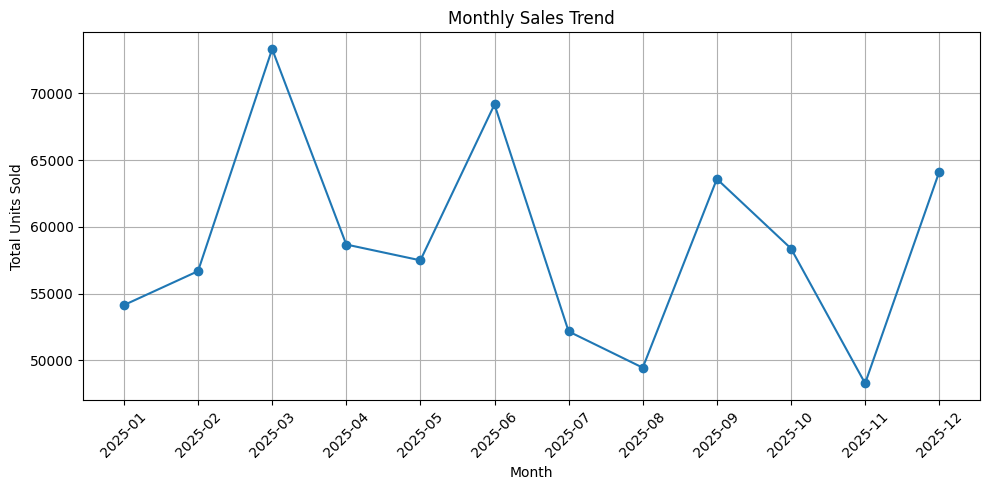

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
#2.weekly stockout_patterns
df["stockout_flag"].value_counts()

,count
stockout_flag,
0,16857
1,303


In [ ]:
weekly_stockout_rate = df.groupby("week_start")["stockout_flag"].mean() * 100

print("Week with highest stockout rate:", weekly_stockout_rate.idxmax())
print("Highest stockout rate:", round(weekly_stockout_rate.max(), 2), "%")

Week with highest stockout rate: 2025-10-13 00:00:00
Highest stockout rate: 6.06 %


Finding: Stockout occurrences varied across weeks. The week starting 13 October 2025 had the highest stockout rate of 6.06%.


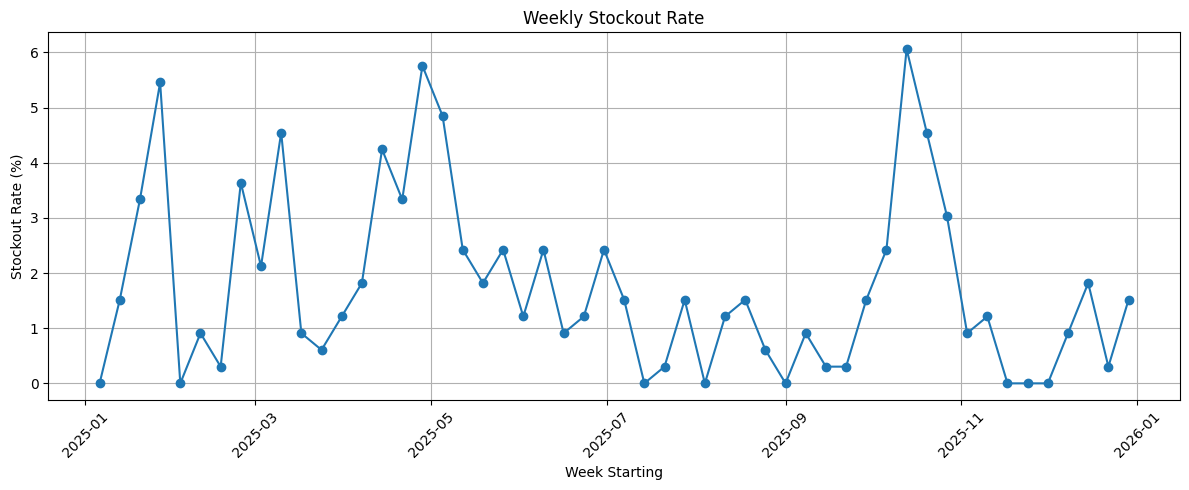

In [ ]:

plt.figure(figsize=(12, 5))
plt.plot(weekly_stockout_rate.index, weekly_stockout_rate.values, marker="o")

plt.title("Weekly Stockout Rate")
plt.xlabel("Week Starting")
plt.ylabel("Stockout Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
#3.Weekly Lost-Sales Patterns
weekly_lost_sales=df.groupby("week_start")["lost_sales_units"].sum()
weekly_lost_sales

,lost_sales_units
week_start,
2025-01-06,0
2025-01-13,30
2025-01-20,121
2025-01-27,262
2025-02-03,0
2025-02-10,22
2025-02-17,11
2025-02-24,119
2025-03-03,26


In [ ]:
print("Week with highest lost sales:", weekly_lost_sales.idxmax())
print("Highest lost-sales units:", weekly_lost_sales.max())

print("Week with lowest lost sales:", weekly_lost_sales.idxmin())
print("Lowest lost-sales units:", weekly_lost_sales.min())

Week with highest lost sales: 2025-10-13 00:00:00
Highest lost-sales units: 426
Week with lowest lost sales: 2025-01-06 00:00:00
Lowest lost-sales units: 0


Finding:Week with highest lost sales: 2025-10-13 00:00:00
Highest lost-sales units: 426
Week with lowest lost sales: 2025-01-06 00:00:00
Lowest lost-sales units: 0

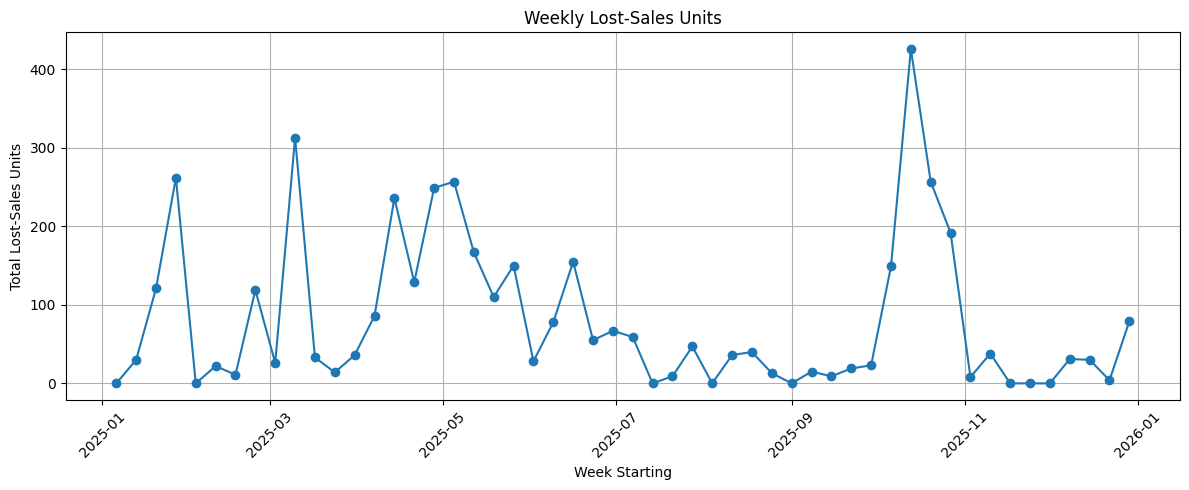

In [ ]:

plt.figure(figsize=(12, 5))
plt.plot(weekly_lost_sales.index, weekly_lost_sales.values, marker="o")

plt.title("Weekly Lost-Sales Units")
plt.xlabel("Week Starting")
plt.ylabel("Total Lost-Sales Units")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
#4 Monthly Spoilage Trend
monthly_spoilage = df.groupby("month")["spoilage_units"].sum()

print(monthly_spoilage)

print("Highest spoilage month:", monthly_spoilage.idxmax())
print("Highest spoilage units:", monthly_spoilage.max())

print("Lowest spoilage month:", monthly_spoilage.idxmin())
print("Lowest spoilage units:", monthly_spoilage.min())

month
2025-01    1884
2025-02    4943
2025-03    4776
2025-04    2672
2025-05    4435
2025-06    4779
2025-07    3055
2025-08    4021
2025-09    4071
2025-10    2998
2025-11    4620
2025-12    4559
Name: spoilage_units, dtype: int64
Highest spoilage month: 2025-02
Highest spoilage units: 4943
Lowest spoilage month: 2025-01
Lowest spoilage units: 1884


Finding: Spoilage varied across the months. February recorded the highest spoilage at 4,943 units, while January recorded the lowest at 1,884 units.

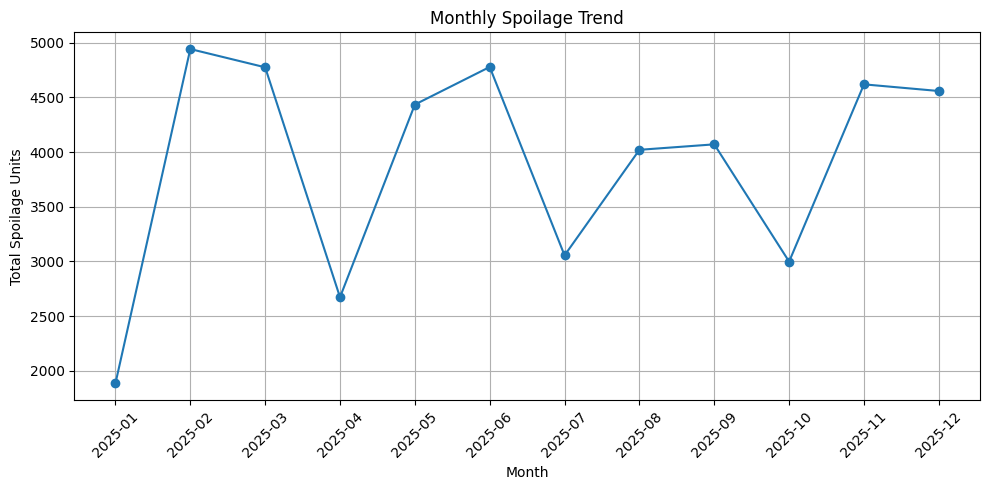

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(monthly_spoilage.index, monthly_spoilage.values, marker="o")

plt.title("Monthly Spoilage Trend")
plt.xlabel("Month")
plt.ylabel("Total Spoilage Units")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:

import pandas as pd

stores = pd.read_excel("/content/drive/MyDrive/Retail_Inventory_Project-cleaned/Retail_Inventory_Project-cleaned.xlsx", sheet_name="stores_table")

print(stores.head())
print(stores.columns)


  store_id        store_name region store_type
0     S001  North Flagship 1  North   Flagship
1     S002  North Standard 2  North   Standard
2     S003  North Standard 3  North   Standard
3     S004   North Express 4  North    Express
4     S005  South Flagship 5  South   Flagship
Index(['store_id', 'store_name', 'region', 'store_type'], dtype='object')


In [ ]:
#5 Stockout Rate by Region

store_stockout_rate = df.groupby("store_id")["stockout_flag"].mean() * 100

print(store_stockout_rate)


store_id
S001    1.136364
S002    2.097902
S003    2.029915
S004    2.257525
S005    1.660839
S006    1.442308
S007    1.794872
S008    1.739927
S009    2.272727
S010    1.518219
S011    1.201923
S012    1.538462
S013    2.403846
S014    1.388889
S015    1.835664
S016    2.029915
Name: stockout_flag, dtype: float64


In [ ]:

store_stockout_rate = store_stockout_rate.reset_index()

store_stockout_rate = store_stockout_rate.rename(
    columns={"stockout_flag": "stockout_rate"}
)

store_details = pd.merge(
    store_stockout_rate,
    stores,
    on="store_id"
)

print(store_details.head())


  store_id  stockout_rate        store_name region store_type
0     S001       1.136364  North Flagship 1  North   Flagship
1     S002       2.097902  North Standard 2  North   Standard
2     S003       2.029915  North Standard 3  North   Standard
3     S004       2.257525   North Express 4  North    Express
4     S005       1.660839  South Flagship 5  South   Flagship


In [ ]:

region_stockout_rate = df.merge(
    stores[["store_id", "region"]],
    on="store_id"
).groupby("region")["stockout_flag"].mean() * 100

print(region_stockout_rate)


region
East     1.628959
North    1.877828
South    1.641651
West     1.923077
Name: stockout_flag, dtype: float64


Finding: West recorded the highest stockout rate at 1.92%, while East recorded the lowest at 1.63%

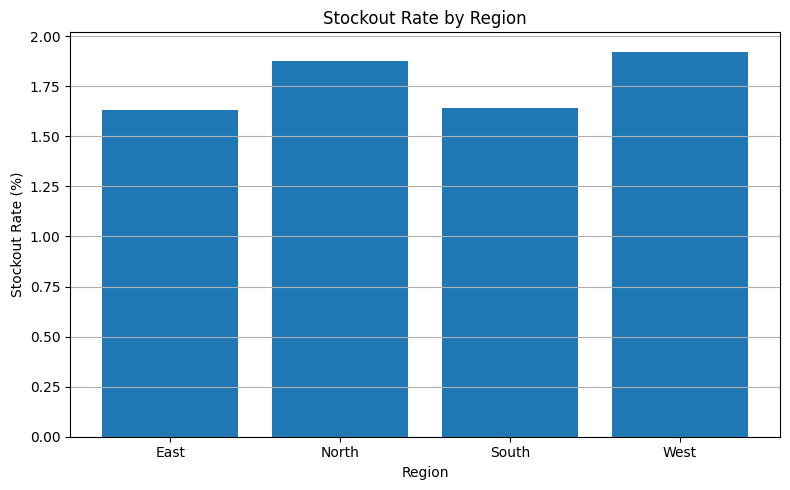

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(region_stockout_rate.index, region_stockout_rate.values)

plt.title("Stockout Rate by Region")
plt.xlabel("Region")
plt.ylabel("Stockout Rate (%)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [ ]:
#6  Supplier-Associated Stockout Rate vs Average Lead Time.
suppliers = pd.read_excel("/content/drive/MyDrive/Retail_Inventory_Project-cleaned/Retail_Inventory_Project-cleaned.xlsx", sheet_name="Suppliers_table")

print(suppliers.head())
print(suppliers.columns)


  supplier_id           supplier_name        category  avg_lead_time_days  \
0      SUP001  Perishables Supplier 1     Perishables                  13   
1      SUP002  Perishables Supplier 2     Perishables                  21   
2      SUP003     Packaged Supplier 1  Packaged Foods                  10   
3      SUP004     Packaged Supplier 2  Packaged Foods                  21   
4      SUP005    Beverages Supplier 1       Beverages                  19   

   reliability_score  
0               0.95  
1               0.92  
2               0.85  
3               0.85  
4               0.83  
Index(['supplier_id', 'supplier_name', 'category', 'avg_lead_time_days',
       'reliability_score'],
      dtype='object')


In [ ]:

print(suppliers.head())
print(suppliers.columns)


  supplier_id           supplier_name        category  avg_lead_time_days  \
0      SUP001  Perishables Supplier 1     Perishables                  13   
1      SUP002  Perishables Supplier 2     Perishables                  21   
2      SUP003     Packaged Supplier 1  Packaged Foods                  10   
3      SUP004     Packaged Supplier 2  Packaged Foods                  21   
4      SUP005    Beverages Supplier 1       Beverages                  19   

   reliability_score  
0               0.95  
1               0.92  
2               0.85  
3               0.85  
4               0.83  
Index(['supplier_id', 'supplier_name', 'category', 'avg_lead_time_days',
       'reliability_score'],
      dtype='object')


In [ ]:

supplier_stockout_rate = df.groupby("supplier_id")["stockout_flag"].mean() * 100

print(supplier_stockout_rate)


supplier_id
SUP001    0.932401
SUP002    2.331002
SUP003    3.379953
SUP004    1.048951
SUP005    1.689977
SUP006    1.981352
SUP007    2.913753
SUP008    0.699301
SUP009    1.223776
SUP010    1.456876
Name: stockout_flag, dtype: float64


In [ ]:
supplier_stockout_rate = supplier_stockout_rate.reset_index()

supplier_stockout_rate = supplier_stockout_rate.rename(
    columns={"stockout_flag": "stockout_rate"}
)

print(supplier_stockout_rate.head())

  supplier_id  stockout_rate
0      SUP001       0.932401
1      SUP002       2.331002
2      SUP003       3.379953
3      SUP004       1.048951
4      SUP005       1.689977


In [ ]:
supplier_analysis = pd.merge(
    supplier_stockout_rate,
    suppliers[["supplier_id", "avg_lead_time_days"]],
    on="supplier_id"
)

print(supplier_analysis)

  supplier_id  stockout_rate  avg_lead_time_days
0      SUP001       0.932401                  13
1      SUP002       2.331002                  21
2      SUP003       3.379953                  10
3      SUP004       1.048951                  21
4      SUP005       1.689977                  19
5      SUP006       1.981352                  15
6      SUP007       2.913753                   6
7      SUP008       0.699301                  13
8      SUP009       1.223776                  18
9      SUP010       1.456876                  15


Findings
1. SUP003 recorded the highest stockout rate at 3.38%, despite having an average lead time of only 10 days.
2. SUP007 had the second-highest stockout rate at 2.91%, even though it had the shortest average lead time of 6 days.
3. SUP002 had the longest average lead time at 21 days, but its stockout rate of 2.33% was lower than SUP003's.
4. Overall interpretation: The supplier-level results do not show a simple pattern where longer average lead times always correspond to higher stockout rates.

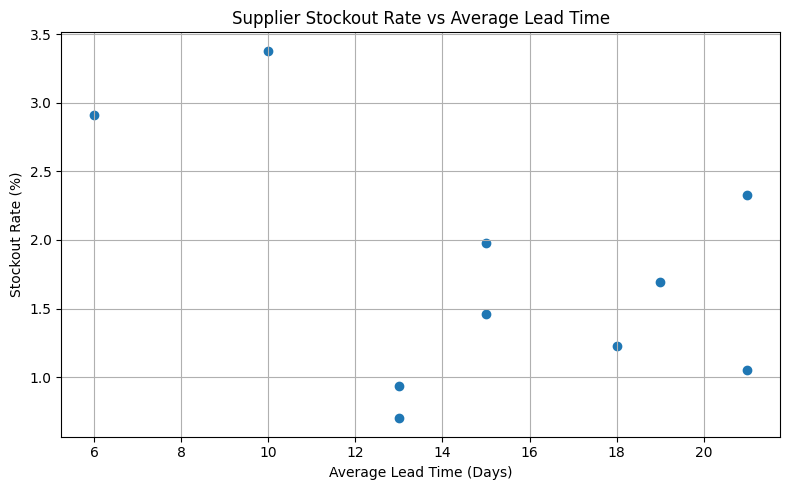

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    supplier_analysis["avg_lead_time_days"],
    supplier_analysis["stockout_rate"]
)

plt.title("Supplier Stockout Rate vs Average Lead Time")
plt.xlabel("Average Lead Time (Days)")
plt.ylabel("Stockout Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()
